# Hotel Booking Cancellation Analysis

**Project type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Dataset:** Hotel booking demand dataset (119,390 booking records in the supplied file)

## Project objective
This project explores hotel booking records to understand cancellation patterns and how they vary by hotel type, arrival month, booking channel/market segment, lead time, deposit type, and customer type.

The notebook preserves the core questions and visual analyses from the original tutorial project, while improving data handling, chart labels, reproducibility, and interpretation.

> **Important interpretation note:** `is_canceled` identifies bookings that were cancelled. ADR is the Average Daily Rate recorded for a booking; it is not, by itself, proof of revenue actually earned. This analysis therefore discusses booking rates and recorded ADR rather than claiming to calculate realized hotel revenue.

## 1. Import libraries and configure the notebook

The notebook uses standard data-analysis libraries. Warnings are not globally suppressed so that useful warnings remain visible.

In [1]:
from pathlib import Path
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

%matplotlib inline

## 2. Load the dataset

Place the downloaded dataset at `data/hotel_booking.csv` in the project root. The uploaded file was named `hotel_booking.xls`, but inspection showed that its contents are comma-separated text (CSV), not an Excel workbook. Rename it to `hotel_booking.csv` before running this notebook.

The search below supports common notebook launch locations.

In [2]:
candidate_paths = [
    Path("data/hotel_booking.csv"),
    Path("../data/hotel_booking.csv"),
    Path("hotel_booking.csv"),
]

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Put the Kaggle CSV at data/hotel_booking.csv "
        "or update DATA_PATH in this cell."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset loaded from: {DATA_PATH}")
print(f"Original shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head()

Dataset loaded from: data/hotel_booking.csv
Original shape: 119,390 rows × 36 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


## 3. Initial inspection and privacy-aware column handling

The supplied file contains guest-identifying fields (`name`, `email`, `phone-number`) and a masked `credit_card` field. These fields are not needed for this analysis and are removed immediately. Do not publish the original dataset containing these columns to a public repository.

The original tutorial also removed `agent` and `company`; these are retained in the raw frame for inspection but excluded from the main analysis because they have substantial missingness and are not required for the questions in this project.

In [3]:
# Keep the loaded source unchanged; work on a separate analysis copy.
df = df_raw.copy()

sensitive_columns = ["name", "email", "phone-number", "credit_card"]
df = df.drop(columns=sensitive_columns, errors="ignore")

print("Shape after removing identifying columns:", df.shape)
display(df.head())

Shape after removing identifying columns: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


### 3.1 Data types, missing values, and duplicate records

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [5]:
missing_summary = (
    df.isna().sum()
      .loc[lambda values: values.gt(0)]
      .sort_values(ascending=False)
      .to_frame("missing_values")
)
missing_summary["missing_percent"] = (
    missing_summary["missing_values"] / len(df) * 100
)
display(missing_summary)

print(f"Duplicate rows: {df.duplicated().sum():,}")

,missing_values,missing_percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


Duplicate rows: 31,994


### 3.2 Convert date fields and inspect categories

`reservation_status_date` records when the reservation status was last set (for example, cancellation or check-out). It is not the same as the guest's planned arrival date. For seasonality analysis, this notebook uses the arrival year, month, and day fields instead.

In [6]:
df["reservation_status_date"] = pd.to_datetime(
    df["reservation_status_date"], errors="coerce"
)

categorical_columns = df.select_dtypes(include=["object"]).columns
for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False).head(15))


hotel:
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

arrival_date_month:
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929
Name: count, dtype: int64

meal:
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

country:
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
USA     2097
CHE     1730
CN      1279
AUT     1263
SWE     1024
Name: count, dtype: int64

market_segment:
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

distrib

## 4. Data cleaning

Cleaning decisions are made explicitly and reported:
- Remove `agent` and `company` from the analysis because their missingness is very high and they are not needed for the questions here.
- Keep rows with missing `country` by labelling them `Unknown`, rather than dropping hundreds of otherwise usable bookings.
- Remove rows with missing `children` (only a small number in the supplied file).
- Exclude impossible negative ADR values and the single extreme ADR value above 5,000. Keep zero ADR values because they may represent complimentary or special bookings; interpret ADR with this in mind.
- Keep the original loaded frame (`df_raw`) unchanged.

In [7]:
rows_before = len(df)

df = df.drop(columns=["agent", "company"], errors="ignore")
df["country"] = df["country"].fillna("Unknown")

df = df.dropna(subset=["children"]).copy()
df = df[df["adr"].ge(0) & df["adr"].le(5000)].copy()

df["children"] = df["children"].astype(int)
df["is_canceled"] = df["is_canceled"].astype(int)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {rows_before - len(df):,}")
print(f"Remaining missing values: {df.isna().sum().sum():,}")
print(f"Duplicate rows after cleaning: {df.duplicated().sum():,}")

Rows before cleaning: 119,390
Rows after cleaning:  119,384
Rows removed:         6


Remaining missing values: 0
Duplicate rows after cleaning: 32,020


### 4.1 Create useful analysis fields

Arrival month is converted to a calendar month number so charts can be displayed in the correct January-to-December order. `total_nights` combines weekday and weekend nights.

In [8]:
month_order = list(calendar.month_name)[1:]
month_number = {month: number for number, month in enumerate(month_order, start=1)}

df["arrival_month_number"] = df["arrival_date_month"].map(month_number)
df["total_nights"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)

df[["hotel", "arrival_date_year", "arrival_date_month",
    "arrival_month_number", "lead_time", "total_nights",
    "adr", "is_canceled"]].head()

,hotel,arrival_date_year,arrival_date_month,arrival_month_number,lead_time,total_nights,adr,is_canceled
0,Resort Hotel,2015,July,7,342,0,0.00,0
1,Resort Hotel,2015,July,7,737,0,0.00,0
2,Resort Hotel,2015,July,7,7,1,75.00,0
3,Resort Hotel,2015,July,7,13,1,75.00,0
4,Resort Hotel,2015,July,7,14,2,98.00,0


## 5. Exploratory data analysis and visualisation

### 5.1 Overall booking cancellation rate

`is_canceled = 1` means cancelled and `is_canceled = 0` means not cancelled.

Overall cancellation rate: 37.04%


,booking_status,bookings,percentage
0,Not cancelled,75165,62.96
1,Cancelled,44219,37.04


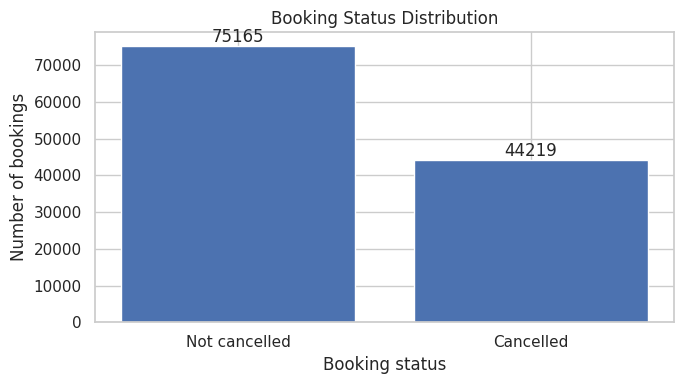

In [9]:
cancellation_counts = df["is_canceled"].value_counts().reindex([0, 1], fill_value=0)
cancellation_rate = df["is_canceled"].mean() * 100

print(f"Overall cancellation rate: {cancellation_rate:.2f}%")
display(
    pd.DataFrame({
        "booking_status": ["Not cancelled", "Cancelled"],
        "bookings": [cancellation_counts.loc[0], cancellation_counts.loc[1]],
        "percentage": [
            cancellation_counts.loc[0] / len(df) * 100,
            cancellation_counts.loc[1] / len(df) * 100
        ]
    })
)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(
    ["Not cancelled", "Cancelled"],
    [cancellation_counts.loc[0], cancellation_counts.loc[1]]
)
ax.set(title="Booking Status Distribution", xlabel="Booking status", ylabel="Number of bookings")
ax.bar_label(bars, fmt="%.0f")
plt.tight_layout()
plt.show()

### 5.2 Cancellation rate by hotel type

This compares the proportion of bookings cancelled at City Hotels and Resort Hotels. Rates are more useful for comparing groups of different sizes than raw counts alone.

,bookings,cancellation_rate
hotel,,
City Hotel,79325,41.72
Resort Hotel,40059,27.76


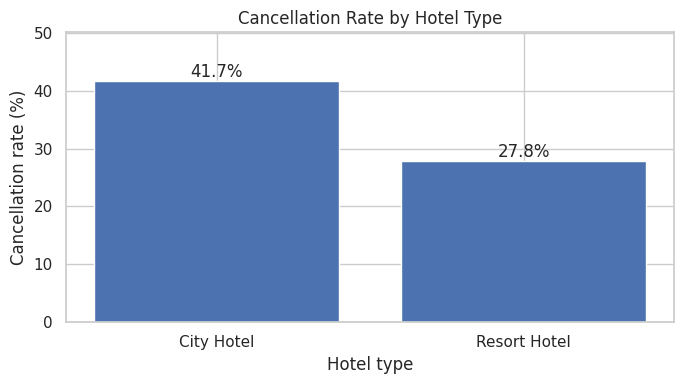

In [10]:
hotel_summary = (
    df.groupby("hotel")["is_canceled"]
      .agg(bookings="size", cancellation_rate="mean")
      .assign(cancellation_rate=lambda x: x["cancellation_rate"] * 100)
      .sort_values("cancellation_rate", ascending=False)
)
display(hotel_summary)

fig, ax = plt.subplots(figsize=(7, 4))
hotel_plot = hotel_summary.reset_index()
bars = ax.bar(hotel_plot["hotel"], hotel_plot["cancellation_rate"])
ax.set(title="Cancellation Rate by Hotel Type", xlabel="Hotel type", ylabel="Cancellation rate (%)")
ax.set_ylim(0, max(hotel_summary["cancellation_rate"]) * 1.2)
ax.bar_label(bars, fmt="%.1f%%")
plt.tight_layout()
plt.show()

### 5.3 Arrival-month cancellation patterns

The original notebook grouped records by `reservation_status_date`. That date reflects when a booking's status was recorded, not the planned stay month. This improved analysis uses `arrival_date_month` and calculates cancellation rate for each arrival month.

,month,bookings,cancelled_bookings,cancellation_rate
arrival_month_number,,,,
1,January,5929,1807,30.48
2,February,8068,2696,33.42
3,March,9792,3148,32.15
4,April,11089,4524,40.80
5,May,11791,4677,39.67
6,June,10939,4535,41.46
7,July,12661,4742,37.45
8,August,13873,5235,37.74
9,September,10508,4116,39.17


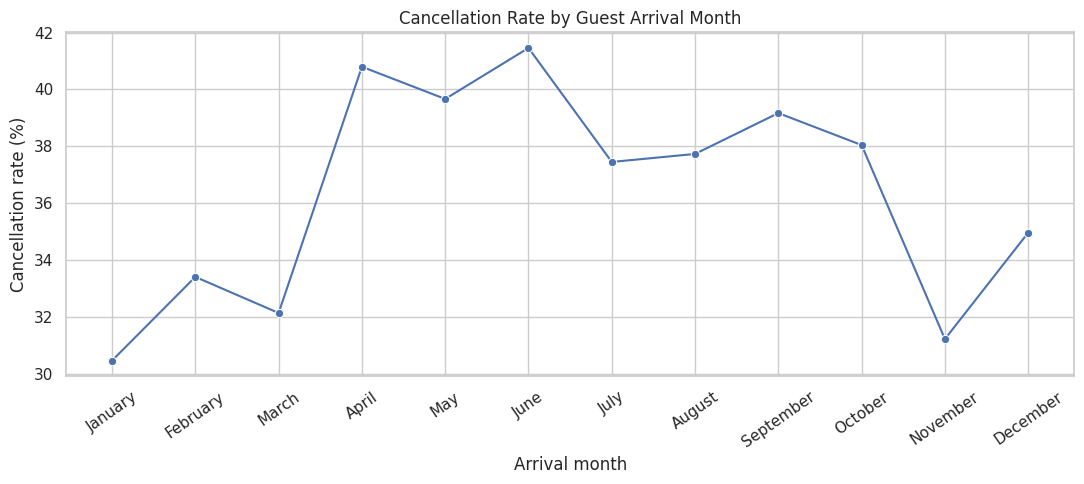

In [11]:
monthly_summary = (
    df.groupby("arrival_month_number")
      .agg(
          bookings=("is_canceled", "size"),
          cancelled_bookings=("is_canceled", "sum"),
          cancellation_rate=("is_canceled", "mean")
      )
      .reindex(range(1, 13))
)
monthly_summary["month"] = [calendar.month_name[m] for m in monthly_summary.index]
monthly_summary["cancellation_rate"] *= 100
display(monthly_summary[["month", "bookings", "cancelled_bookings", "cancellation_rate"]])

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=monthly_summary, x="month", y="cancellation_rate", marker="o", ax=ax)
ax.set(title="Cancellation Rate by Guest Arrival Month", xlabel="Arrival month", ylabel="Cancellation rate (%)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### 5.4 Average Daily Rate (ADR) by arrival month and hotel type

This shows the average recorded ADR for bookings by planned arrival month. It is a descriptive comparison, not a measure of revenue received.

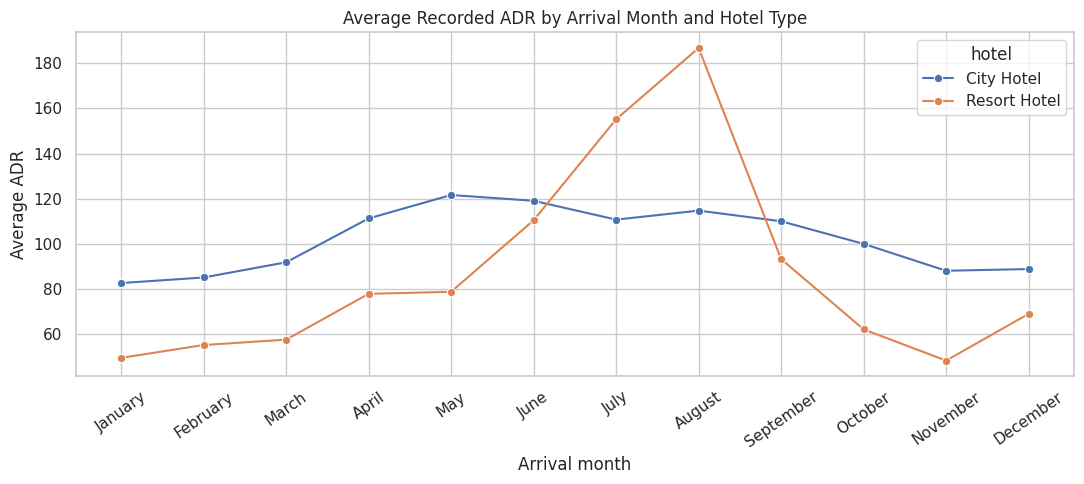

In [12]:
adr_monthly = (
    df.groupby(["arrival_month_number", "hotel"], as_index=False)["adr"]
      .mean()
)
adr_monthly["month"] = adr_monthly["arrival_month_number"].map(
    lambda number: calendar.month_name[number]
)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(
    data=adr_monthly, x="month", y="adr", hue="hotel",
    marker="o", ax=ax
)
ax.set(title="Average Recorded ADR by Arrival Month and Hotel Type",
       xlabel="Arrival month", ylabel="Average ADR")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### 5.5 Countries with the highest number of cancelled bookings

This chart ranks countries by cancellation count. It shows volume, not each country's cancellation rate; countries with more bookings may naturally have more cancellations.

,cancelled_bookings
country,
PRT,27514
GBR,2453
ESP,2177
FRA,1934
ITA,1333
DEU,1218
IRL,832
BRA,830
USA,501


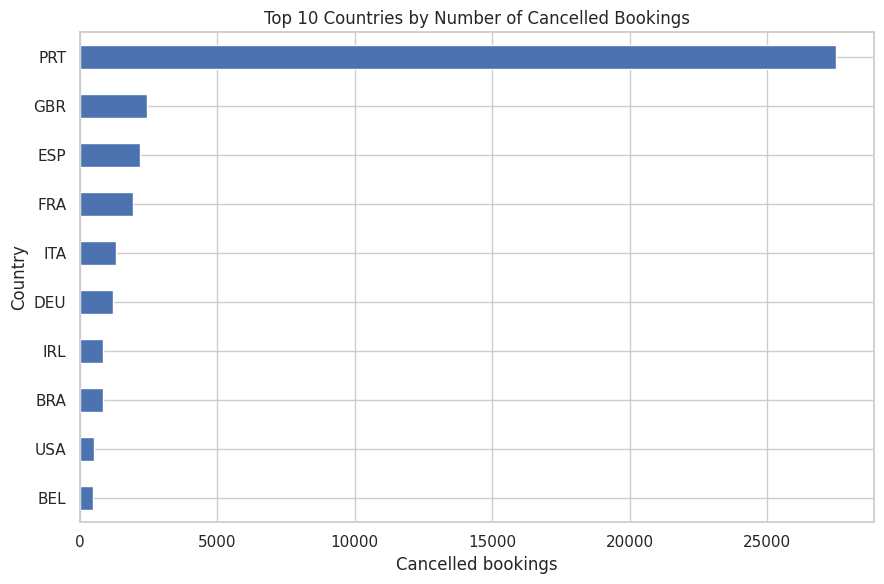

In [13]:
cancelled_data = df.loc[df["is_canceled"].eq(1)].copy()
top_countries = (
    cancelled_data["country"]
    .value_counts()
    .head(10)
    .sort_values()
)

display(top_countries.sort_values(ascending=False).to_frame("cancelled_bookings"))

fig, ax = plt.subplots(figsize=(9, 6))
top_countries.plot(kind="barh", ax=ax)
ax.set(title="Top 10 Countries by Number of Cancelled Bookings",
       xlabel="Cancelled bookings", ylabel="Country")
plt.tight_layout()
plt.show()

### 5.6 Cancellation rate by market segment

Market segments differ in size. This analysis displays both booking volume and cancellation rate to avoid relying only on counts.

,bookings,cancellation_rate
market_segment,,
Groups,19810,61.07
Online TA,56476,36.72
Offline TA/TO,24218,34.31
Aviation,237,21.94
Corporate,5295,18.73
Direct,12605,15.34
Complementary,743,13.06


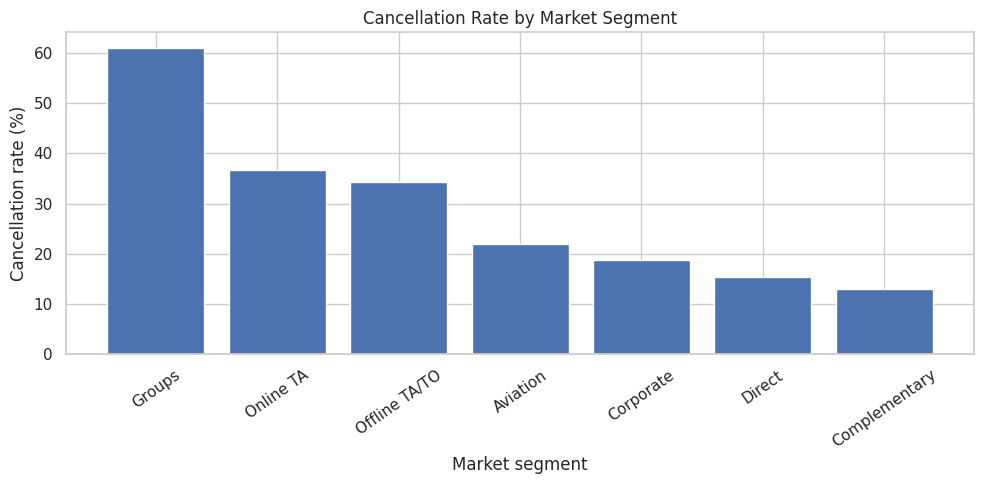

In [14]:
segment_summary = (
    df.groupby("market_segment")["is_canceled"]
      .agg(bookings="size", cancellation_rate="mean")
      .assign(cancellation_rate=lambda x: x["cancellation_rate"] * 100)
      .sort_values("cancellation_rate", ascending=False)
)
display(segment_summary)

fig, ax = plt.subplots(figsize=(10, 5))
segment_plot = segment_summary.reset_index()
bars = ax.bar(segment_plot["market_segment"], segment_plot["cancellation_rate"])
ax.set(title="Cancellation Rate by Market Segment",
       xlabel="Market segment", ylabel="Cancellation rate (%)")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### 5.7 Lead time and cancellation

Lead time is the number of days between booking and arrival. Compare the distribution for cancelled and non-cancelled bookings. The median is included because lead-time distributions can be skewed.

,bookings,mean,median
is_canceled,,,
Not cancelled,75165,79.98,45.00
Cancelled,44219,144.86,113.00


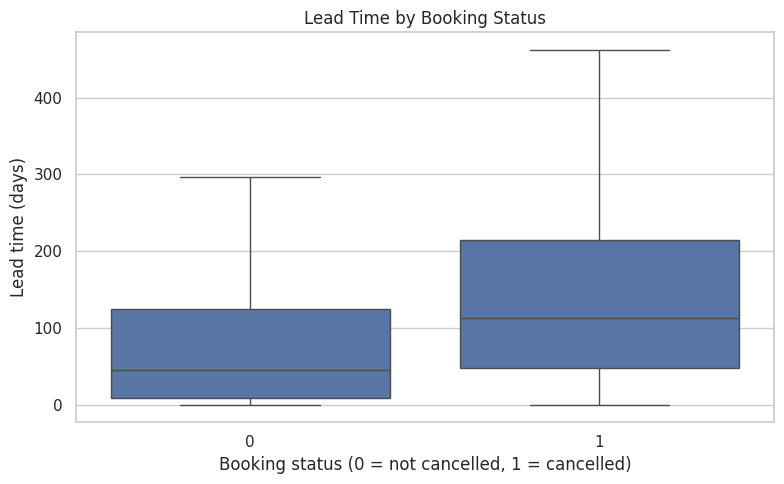

In [15]:
lead_time_summary = (
    df.groupby("is_canceled")["lead_time"]
      .agg(bookings="size", mean="mean", median="median")
      .rename(index={0: "Not cancelled", 1: "Cancelled"})
)
display(lead_time_summary)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="is_canceled", y="lead_time", showfliers=False, ax=ax)
ax.set(title="Lead Time by Booking Status",
       xlabel="Booking status (0 = not cancelled, 1 = cancelled)",
       ylabel="Lead time (days)")
plt.tight_layout()
plt.show()

### 5.8 Cancellation rate by deposit type

,bookings,cancellation_rate
deposit_type,,
Non Refund,14586,99.36
No Deposit,104636,28.37
Refundable,162,22.22


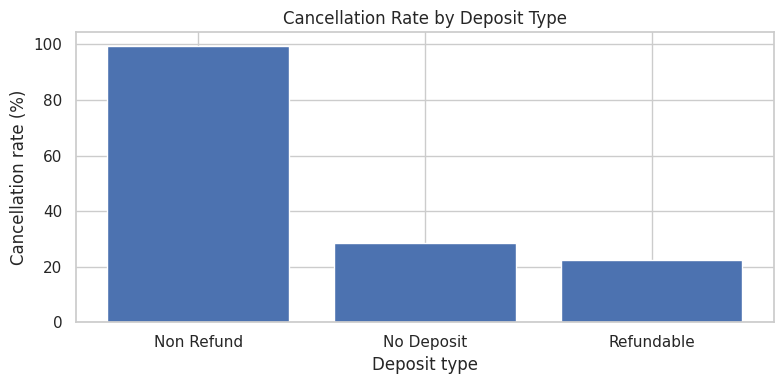

In [16]:
deposit_summary = (
    df.groupby("deposit_type")["is_canceled"]
      .agg(bookings="size", cancellation_rate="mean")
      .assign(cancellation_rate=lambda x: x["cancellation_rate"] * 100)
      .sort_values("cancellation_rate", ascending=False)
)
display(deposit_summary)

fig, ax = plt.subplots(figsize=(8, 4))
deposit_plot = deposit_summary.reset_index()
bars = ax.bar(deposit_plot["deposit_type"], deposit_plot["cancellation_rate"])
ax.set(title="Cancellation Rate by Deposit Type",
       xlabel="Deposit type", ylabel="Cancellation rate (%)")
plt.tight_layout()
plt.show()

### 5.9 Cancellation rate by customer type

,bookings,cancellation_rate
customer_type,,
Transient,89612,40.75
Contract,4076,30.96
Transient-Party,25119,25.42
Group,577,10.23


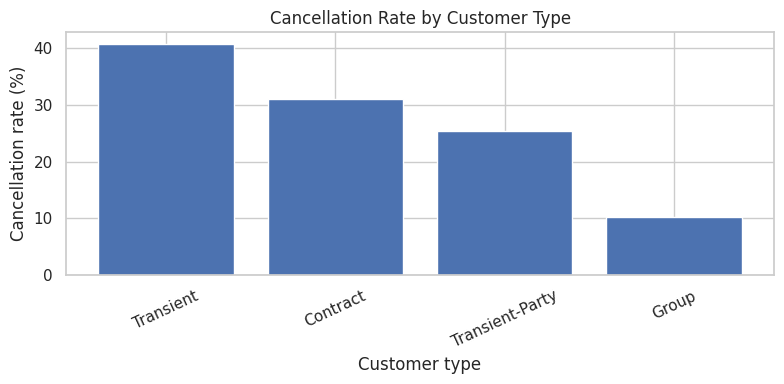

In [17]:
customer_summary = (
    df.groupby("customer_type")["is_canceled"]
      .agg(bookings="size", cancellation_rate="mean")
      .assign(cancellation_rate=lambda x: x["cancellation_rate"] * 100)
      .sort_values("cancellation_rate", ascending=False)
)
display(customer_summary)

fig, ax = plt.subplots(figsize=(8, 4))
customer_plot = customer_summary.reset_index()
bars = ax.bar(customer_plot["customer_type"], customer_plot["cancellation_rate"])
ax.set(title="Cancellation Rate by Customer Type",
       xlabel="Customer type", ylabel="Cancellation rate (%)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 6. Key findings

The following summary values are calculated from the cleaned dataset when the notebook is run. They are descriptive associations and should not be interpreted as proof that a factor causes cancellation.

In [18]:
print(f"Cleaned bookings analysed: {len(df):,}")
print(f"Overall cancellation rate: {df['is_canceled'].mean() * 100:.2f}%")

hotel_rates = df.groupby("hotel")["is_canceled"].mean().mul(100).sort_values(ascending=False)
print("\nCancellation rate by hotel:")
display(hotel_rates.rename("cancellation_rate_percent").to_frame())

lead_medians = df.groupby("is_canceled")["lead_time"].median()
print("\nMedian lead time (days):")
print(f"Not cancelled: {lead_medians.loc[0]:.0f}")
print(f"Cancelled:     {lead_medians.loc[1]:.0f}")

print("\nCancellation rate by deposit type:")
display(deposit_summary)

Cleaned bookings analysed: 119,384
Overall cancellation rate: 37.04%

Cancellation rate by hotel:


,cancellation_rate_percent
hotel,
City Hotel,41.72
Resort Hotel,27.76



Median lead time (days):
Not cancelled: 45
Cancelled:     113

Cancellation rate by deposit type:


,bookings,cancellation_rate
deposit_type,,
Non Refund,14586,99.36
No Deposit,104636,28.37
Refundable,162,22.22


## 7. Business recommendations

Use the results above to formulate evidence-based recommendations. Examples to evaluate against the actual outputs:

1. Review cancellation patterns for hotel types and market segments with higher cancellation rates.
2. Consider booking policies and reminder/confirmation processes for bookings made far in advance.
3. Evaluate deposit and refund policies carefully; compare cancellation rates alongside booking volumes and customer experience.
4. Use arrival-month patterns to support staffing and inventory planning.
5. Monitor both cancellation rate and booking volume so that small segments do not dominate decisions based on percentages alone.

These are potential actions for further investigation, not guaranteed ways to reduce cancellations.

## 8. Limitations

- This is observational booking data; relationships do not establish causation.
- ADR is a recorded average daily rate and does not equal realized revenue.
- The country chart shows cancellation counts, not country-level cancellation rates.
- `reservation_status_date` is not the same as the planned arrival date; arrival fields are used for seasonality analysis.
- A small number of rows were removed for missing children values or invalid/extreme ADR values; the cleaning summary above reports the resulting row count.
- The source file contains guest-identifying columns. Those columns are excluded from analysis, and the raw file should not be committed to a public GitHub repository.

## 9. Reproducibility

Install the packages listed in `requirements.txt`, place the Kaggle CSV at `data/hotel_booking.csv`, and run all notebook cells from top to bottom.

**Author:** Aaliya Shaikh